In [1]:
import time
import copy

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import joblib

import torch
import torch.nn as nn

from utils import get_opt, get_loaders, eval_ppl
from predictor_definitions import LogisticRegression, MLPClassifier

In [2]:
DEV = torch.device('cuda:0') if torch.cuda.is_available() else torch.device('cpu')
layers_to_keep = (0, 1, 23)

# Loading

## Model

In [33]:
# model_name = "HuggingFaceTB/SmolLM2-135M"
# model_name = "HuggingFaceTB/SmolLM2-360M"
model_name = "HuggingFaceTB/SmolLM2-1.7B"

model = get_opt(model_name)
model.eval()
model.to(DEV)

LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(49152, 2048)
    (layers): ModuleList(
      (0-23): 24 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (k_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (v_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (o_proj): Linear(in_features=2048, out_features=2048, bias=False)
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (up_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (down_proj): Linear(in_features=8192, out_features=2048, bias=False)
          (act_fn): SiLU()
        )
        (input_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
        (post_attention_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
      )
    )
    (norm): LlamaRMSNorm((2048,), eps=1e-05)
    (rotary_emb)

## Predictors

In [34]:
for i, layer in enumerate(model.model.layers):
    if i in layers_to_keep: 
        continue
    layer.predictor = {}
    layer.predictor['lr'] = joblib.load(f'predictors_rel_L1/cls_model_layer{i}.pkl')
    layer.predictor['nn'] = joblib.load(f'predictors_rel_L1/cls_model_mlp_layer{i}.pkl')

## Data

In [8]:
wiki_dataloader, wiki_testloader = get_loaders(
    'wikitext2', seed=0, model=model_name, seqlen=model.seqlen
)

Token indices sequence length is longer than the specified maximum sequence length for this model (2565857 > 8192). Running this sequence through the model will result in indexing errors


ts torch.Size([1, 2565857])


# Router

In [6]:
class MLPRouter(nn.Module):
    def __init__(self, predictor, mlp, save_bitmap=False):
        super().__init__()
        self.predictor = predictor
        self.mlp = mlp
        self.n_total = 0
        self.n_mlp = 0
        self.save_bitmap = save_bitmap
        if save_bitmap:
            self.bitmap = []
        
    def forward(self, x):
        use_mlp = self.predictor.predict(x.to(torch.float)).astype(bool)
        # print(use_mlp.flatten().sum())
        bsz, seq_len, dim = x.shape
        x_flat = x.view(-1, dim)
        use_mlp_flat = use_mlp.flatten()  # shape: (bsz * seq_len)
        self.n_mlp += use_mlp_flat.sum()
        self.n_total += use_mlp_flat.size
        # Apply MLP only to selected tokens
        out = torch.zeros_like(x_flat)  # same shape as input
        if use_mlp_flat.any():
            selected = x_flat[use_mlp_flat]  # (N_selected, dim)
            mlp_out = self.mlp(selected)     # (N_selected, dim)
            out[use_mlp_flat] = mlp_out      # insert results
            if self.save_bitmap:
                self.bitmap.extend(use_mlp_flat.tolist())

        return out.view(bsz, seq_len, dim)
        

# Evaluate pruned model

In [17]:
def eval_model(use_router='', results_router=None, layer_stats=None, auc_thr=-1, AUC_data='prediction_results.csv', save_bitmap=False):
    if layer_stats is None:
        layer_stats = pd.DataFrame()
    if results_router is None:
        results_router = pd.DataFrame(columns=["perplexity", "del_ratio", "inference_time"])

    if use_router:
        predictor_quality = pd.read_csv(AUC_data, index_col=0)
        auc_col = 'AUC' if 'lr' in use_router else 'AUC_mlp'
        
        # replace MLP with router only if the AUC is high enough for the layer
        for i, layer in enumerate(model.model.layers):
            if i in layers_to_keep or predictor_quality.loc[i, auc_col] < auc_thr:
                continue
            predictor = layer.predictor[use_router]
            mlp_copy = copy.deepcopy(layer.mlp)
            layer.mlp = MLPRouter(predictor, mlp_copy, save_bitmap=save_bitmap)
    
    # measure performance
    t0 = time.time()
    ppl = eval_ppl(model, wiki_testloader, device=DEV)
    t = time.time() - t0

    global_skip_ratio = 0
    routing_bitmap = []
    
    if use_router:
        sum_n_total = sum_n_skipped = 0
        column_name = use_router

        for i, layer in enumerate(model.model.layers):
            if i in layers_to_keep or predictor_quality.loc[i, auc_col] < auc_thr:
                continue

            n_total = layer.mlp.n_total
            n_skipped = n_total - layer.mlp.n_mlp
            skip_ratio = n_skipped / n_total if n_total > 0 else 0

            sum_n_skipped += n_skipped
            
            if save_bitmap:
                routing_bitmap.append(layer.mlp.bitmap)

            layer_stats.at[i, column_name] = skip_ratio
            layer.mlp = copy.deepcopy(layer.mlp.mlp)  # restore

        sum_n_total = n_total * len(model.model.layers)
        global_skip_ratio = sum_n_skipped / sum_n_total
        layer_stats.at['all', column_name] = global_skip_ratio
    
    results_router.loc[use_router] = [ppl, global_skip_ratio, t]
    return {'results_router': results_router, 'layer_stats': layer_stats, 'routing_bitmap': routing_bitmap}

In [18]:
results_dict = eval_model('lr', save_bitmap=True)
bitmap_lr = results_dict['routing_bitmap']
results_dict = eval_model('nn', results_router=results_dict['results_router'], layer_stats=results_dict['layer_stats'], save_bitmap=True)
bitmap_mlp = results_dict['routing_bitmap']
results_dict = eval_model('', results_router=results_dict['results_router'], layer_stats=results_dict['layer_stats'], save_bitmap=True)
results_dict['results_router'].to_csv('results_router.csv')
results_dict['results_router']

,perplexity,del_ratio,inference_time
lr,8.746975,0.092178,9.414994
nn,1077.354248,0.318026,8.562652
,7.260689,0.000000,9.242558


## Visualization of routing

In [9]:
pd.DataFrame(bitmap_lr).to_csv('bitmap_lr.csv')
pd.DataFrame(bitmap_mlp).to_csv('bitmap_mlp.csv')

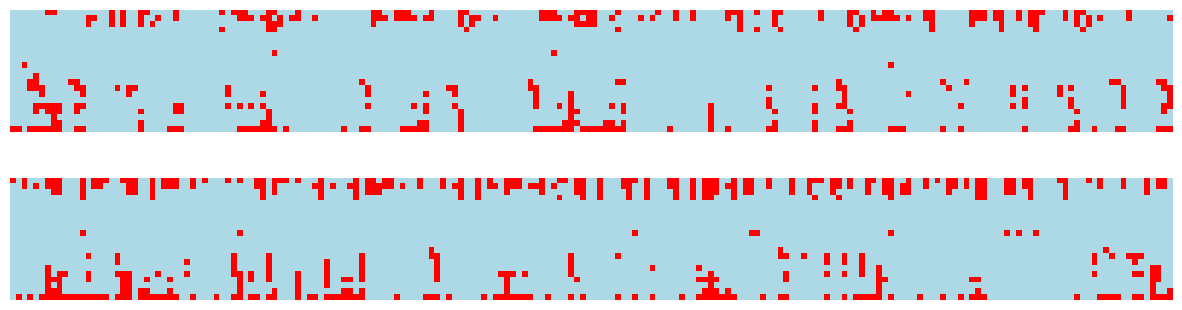

In [77]:
# bitmap of routing using LR
cmap = ListedColormap(["red", "lightblue"])  # skipped=red

fig, axs = plt.subplots(2, 1, figsize=(15, 4))

bitmap_lr_slice = [row[:200] for row in bitmap_lr]
axs[0].imshow(bitmap_lr_slice, cmap=cmap, interpolation="nearest")
axs[0].axis("off")
bitmap_lr_slice = [row[250000:250200] for row in bitmap_lr]
axs[1].imshow(bitmap_lr_slice, cmap=cmap, interpolation="nearest")
axs[1].axis("off")
plt.show()

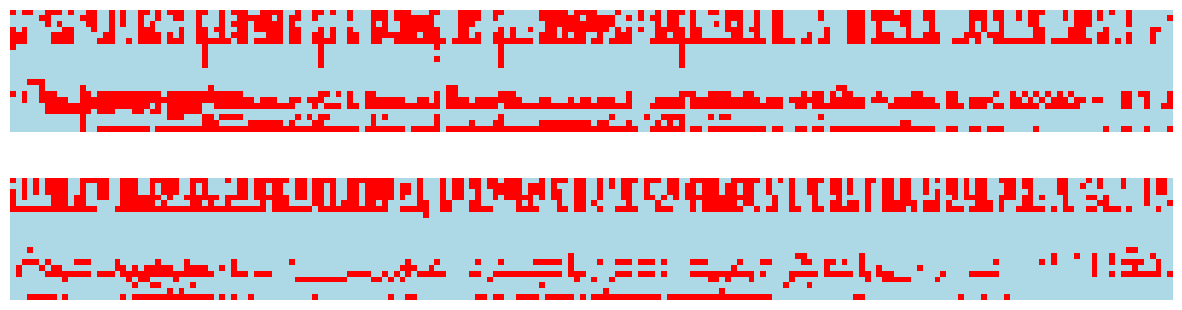

In [76]:
# bitmap of routing using MLP
bitmap_mlp_slice = [row[:200] for row in bitmap_mlp]

fig, axs = plt.subplots(2, 1, figsize=(15, 4))
axs[0].imshow(bitmap_mlp_slice, cmap=cmap, interpolation="nearest")
axs[0].axis("off")

bitmap_mlp_slice = [row[250000:250200] for row in bitmap_mlp]
axs[1].imshow(bitmap_mlp_slice, cmap=cmap, interpolation="nearest")
axs[1].axis("off")
plt.show()

## Ratio of tokens routed around the MLP

In [12]:
results_dict['layer_stats']

,lr,nn
2,0.385063,0.536341
3,0.399698,0.480215
4,0.150622,0.371156
5,0.062253,0.396936
6,0.000000,0.363308
7,0.001554,0.616119
8,0.000287,0.277390
9,0.003471,0.279831
10,0.000132,0.154627
11,0.049274,0.142337


# Eval pruned model using only predictors with AUC > thr

In [23]:
results_thr_dict = eval_model('lr', auc_thr=0.85)
results_thr_dict = eval_model('nn', results_router=results_thr_dict['results_router'], layer_stats=results_thr_dict['layer_stats'], auc_thr=0.85)
results_thr_dict = eval_model('', results_router=results_thr_dict['results_router'], layer_stats=results_thr_dict['layer_stats'], auc_thr=0.85)
results_thr_dict['results_router'].to_csv('results_router_thr.csv')
results_thr_dict['results_router']

,perplexity,del_ratio,inference_time
lr,8.362296,0.076231,9.124693
nn,77.288940,0.196867,8.752831
,7.260689,0.000000,9.296019


In [16]:
results_thr_dict['layer_stats']

,lr,nn
2,0.385063,0.536341
3,0.399698,0.480215
4,0.150622,0.371156
5,0.062253,0.396936
6,0.000000,0.363308
7,0.001554,NaN
8,0.000287,NaN
9,0.003471,NaN
10,0.000132,NaN
13,0.000379,NaN


---
# Top-k router

In [23]:
class MLPRouterTopK(nn.Module):
    def __init__(self, predictor, mlp, k=0.7, save_bitmap=False):
        super().__init__()
        self.predictor = predictor
        self.mlp = mlp
        self.k = k
        self.n_total = 0
        self.n_mlp = 0
        self.save_bitmap = save_bitmap
        if save_bitmap:
            self.bitmap = []
        
    def forward(self, x):
        # compute logits
        use_mlp_probs = torch.Tensor(self.predictor.predict_proba(x.to(torch.float)))
        bsz, seq_len, dim = x.shape
        x_flat = x.view(-1, dim)

        k_per_row = max(1, int(seq_len * self.k))  # ensure at least 1
        selected_idx = torch.topk(use_mlp_probs, k_per_row, dim=1).indices.flatten()  # (bsz, k_per_row)
        
        self.n_mlp += selected_idx.numel()
        self.n_total += use_mlp_probs.numel()
        # Apply MLP only to selected tokens
        out = torch.zeros_like(x_flat)  # same shape as input
        if selected_idx.numel():
            selected = x_flat[selected_idx]  # (N_selected, dim)
            mlp_out = self.mlp(selected)     # (N_selected, dim)
            out[selected_idx] = mlp_out      # insert results
            if self.save_bitmap:
                self.bitmap.extend(selected_idx.tolist())

        return out.view(bsz, seq_len, dim)
        

In [24]:
def eval_model_topk(use_router='', results_router=None, layer_stats=None, k=0.7, save_bitmap=False):
    if results_router is None:
        index = pd.MultiIndex.from_tuples([], names=["k", "router_type"])
        results_router = pd.DataFrame(columns=["perplexity", "del_ratio", "inference_time"], index=index)

    if use_router:
        predictor_quality = pd.read_csv('prediction_results.csv', index_col=0)
        auc_col = 'AUC' if use_router == 'lr' else 'AUC_mlp'
        
        # replace MLP with router only if the AUC is high enough for the layer
        for i, layer in enumerate(model.model.layers):
            if i in layers_to_keep:
                continue
            predictor = layer.predictor[use_router]
            mlp_copy = copy.deepcopy(layer.mlp)
            layer.mlp = MLPRouterTopK(predictor, mlp_copy, k=k, save_bitmap=save_bitmap)
    
    # measure performance
    t0 = time.time()
    ppl = eval_ppl(model, wiki_testloader, device=DEV)
    t = time.time() - t0

    global_skip_ratio = 0
    routing_bitmap = []
    
    if use_router:
        sum_n_total = sum_n_skipped = 0
        column_name = use_router

        for i, layer in enumerate(model.model.layers):
            if i in layers_to_keep:
                continue

            n_total = layer.mlp.n_total
            n_skipped = n_total - layer.mlp.n_mlp
            skip_ratio = n_skipped / n_total if n_total > 0 else 0

            sum_n_skipped += n_skipped

            if save_bitmap:
                routing_bitmap.append(layer.mlp.bitmap)

            layer.mlp = copy.deepcopy(layer.mlp.mlp)  # restore

        sum_n_total = n_total * len(model.model.layers)
        global_skip_ratio = sum_n_skipped / sum_n_total
    
    results_router.loc[(k, use_router), :] = [ppl, global_skip_ratio, t]
    return {'results_router': results_router, 'routing_bitmap': routing_bitmap}

In [25]:
results_topk_dict = eval_model_topk('lr', k=0.7)
results_topk_dict = eval_model_topk('nn', k=0.7, results_router=results_topk_dict['results_router'])
results_topk_dict = eval_model_topk('lr', k=0.8, results_router=results_topk_dict['results_router'])
results_topk_dict = eval_model_topk('nn', k=0.8, results_router=results_topk_dict['results_router'])
results_topk_dict = eval_model_topk('lr', k=0.9, results_router=results_topk_dict['results_router'], save_bitmap=True)
bitmap_topk_lr = results_topk_dict['routing_bitmap']
results_topk_dict = eval_model_topk('nn', k=0.9, results_router=results_topk_dict['results_router'], save_bitmap=True)
bitmap_topk_mlp = results_topk_dict['routing_bitmap']

results_topk_dict['results_router'].to_csv('results_router_topk.csv')
results_topk_dict['results_router']

perplexity del_ratio inference_time
k   router_type                                     
0.7 lr           750.528137  0.262543       8.919242
    nn           615.155457  0.262543       8.884506
0.8 lr             524.1745  0.175064       9.177092
    nn            316.98938  0.175064       9.271467
0.9 lr            57.097687  0.087585       9.774607
    nn             8.485021  0.087585       9.860854

In [26]:
pd.DataFrame(bitmap_topk_lr).to_csv('bitmap_topk_lr.csv')
pd.DataFrame(bitmap_topk_mlp).to_csv('bitmap_topk_mlp.csv')

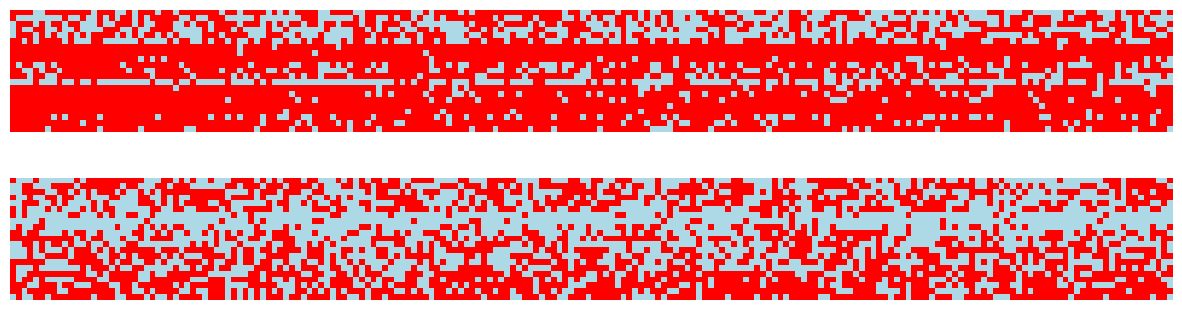

In [27]:
# bitmap of routing using LR
cmap = ListedColormap(["red", "lightblue"])  # skipped=red

fig, axs = plt.subplots(2, 1, figsize=(15, 4))
bitmap_lr_slice = [row[:200] for row in bitmap_topk_lr]
axs[0].imshow(bitmap_lr_slice, cmap=cmap, interpolation="nearest")
axs[0].axis("off")
bitmap_lr_slice = [row[250000:250200] for row in bitmap_topk_lr]
axs[1].imshow(bitmap_lr_slice, cmap=cmap, interpolation="nearest")
axs[1].axis("off")
plt.show()

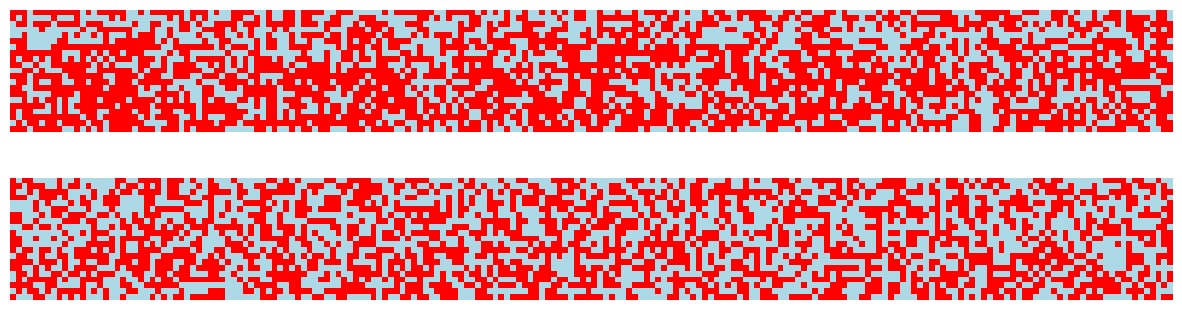

In [28]:
# bitmap of routing using MLP
fig, axs = plt.subplots(2, 1, figsize=(15, 4))

bitmap_mlp_slice = [row[:200] for row in bitmap_topk_mlp]
axs[0].imshow(bitmap_mlp_slice, cmap=cmap, interpolation="nearest")
axs[0].axis("off")
bitmap_mlp_slice = [row[250000:250200] for row in bitmap_topk_mlp]
axs[1].imshow(bitmap_mlp_slice, cmap=cmap, interpolation="nearest")
axs[1].axis("off")
plt.show()

# Not skipping two layers in row

In [84]:
a = np.array([1, 1, 0, 0]).astype(bool)
b = np.array([1, 0, 1, 0]).astype(bool)
(a | ~b).astype(int)

array([1, 1, 0, 1])

In [75]:
class SingleSkipRouter(nn.Module):
    def __init__(self, predictor, mlp, prev_router=None, save_bitmap=True):
        super().__init__()
        self.predictor = predictor
        self.mlp = mlp
        self.prev_router = prev_router
        self.n_total = 0
        self.n_mlp = 0
        self.save_bitmap = save_bitmap
        if save_bitmap:
            self.bitmap = []
        self.latest_decision = []
        
    def forward(self, x):
        use_mlp = self.predictor.predict(x.to(torch.float)).astype(bool)
        # print(use_mlp.flatten().sum())
        bsz, seq_len, dim = x.shape
        x_flat = x.view(-1, dim)
        use_mlp_flat = use_mlp.flatten()  # shape: (bsz * seq_len)
        # avoid skipping two layers in a row for the same token
        previous = self.prev_router.latest_decision if self.prev_router else np.ones_like(use_mlp_flat).astype(bool)
        use_mlp_flat = use_mlp_flat | ~previous
        
        self.n_mlp += use_mlp_flat.sum()
        self.n_total += use_mlp_flat.size
        # Apply MLP only to selected tokens
        out = torch.zeros_like(x_flat)  # same shape as input
        if use_mlp_flat.any():
            selected = x_flat[use_mlp_flat]  # (N_selected, dim)
            mlp_out = self.mlp(selected)     # (N_selected, dim)
            out[use_mlp_flat] = mlp_out      # insert results
            self.latest_decision = use_mlp_flat
            if self.save_bitmap:
                self.bitmap.extend(use_mlp_flat.tolist())

        return out.view(bsz, seq_len, dim)
        

In [76]:
def eval_model_singleskip(use_router='', results_router=None, layer_stats=None, auc_thr=-1, AUC_data='prediction_results.csv', save_bitmap=False):
    if layer_stats is None:
        layer_stats = pd.DataFrame()
    if results_router is None:
        results_router = pd.DataFrame(columns=["perplexity", "del_ratio", "inference_time"])

    if use_router:
        predictor_quality = pd.read_csv(AUC_data, index_col=0)
        auc_col = 'AUC' if 'lr' in use_router else 'AUC_mlp'
        prev_router = None

        for i, layer in enumerate(model.model.layers):
            if i in layers_to_keep or predictor_quality.loc[i, auc_col] < auc_thr:
                prev_router = None
                continue
            predictor = layer.predictor[use_router]
            mlp_copy = copy.deepcopy(layer.mlp)
            layer.mlp = SingleSkipRouter(predictor, mlp_copy, prev_router=prev_router, save_bitmap=save_bitmap)
            prev_router = layer.mlp
    
    # measure performance
    t0 = time.time()
    ppl = eval_ppl(model, wiki_testloader, device=DEV)
    t = time.time() - t0

    global_skip_ratio = 0
    routing_bitmap = []
    
    if use_router:
        sum_n_total = sum_n_skipped = 0
        column_name = use_router

        for i, layer in enumerate(model.model.layers):
            if i in layers_to_keep or predictor_quality.loc[i, auc_col] < auc_thr:
                continue

            n_total = layer.mlp.n_total
            n_skipped = n_total - layer.mlp.n_mlp
            skip_ratio = n_skipped / n_total if n_total > 0 else 0

            sum_n_skipped += n_skipped
            
            if save_bitmap:
                routing_bitmap.append(layer.mlp.bitmap)

            layer_stats.at[i, column_name] = skip_ratio
            layer.mlp = copy.deepcopy(layer.mlp.mlp)  # restore

        sum_n_total = n_total * len(model.model.layers)
        global_skip_ratio = sum_n_skipped / sum_n_total
        layer_stats.at['all', column_name] = global_skip_ratio
    
    results_router.loc[use_router] = [ppl, global_skip_ratio, t]
    return {'results_router': results_router, 'layer_stats': layer_stats, 'routing_bitmap': routing_bitmap}

In [77]:
results_singleskip_dict = eval_model_singleskip('lr', save_bitmap=True)
bitmap_singleskip_lr = results_singleskip_dict['routing_bitmap']
results_singleskip_dict = eval_model_singleskip('nn', results_router=results_singleskip_dict['results_router'], layer_stats=results_singleskip_dict['layer_stats'], save_bitmap=True)
bitmap_singleskip_mlp = results_singleskip_dict['routing_bitmap']
results_singleskip_dict = eval_model_singleskip('', results_router=results_singleskip_dict['results_router'], layer_stats=results_singleskip_dict['layer_stats'], save_bitmap=True)
results_singleskip_dict['results_router'].to_csv('results_singleskip_router.csv')
results_singleskip_dict['results_router']

,perplexity,del_ratio,inference_time
lr,8.041942,0.064213,9.456924
nn,14.857131,0.228014,8.894479
,7.260689,0.000000,9.215948


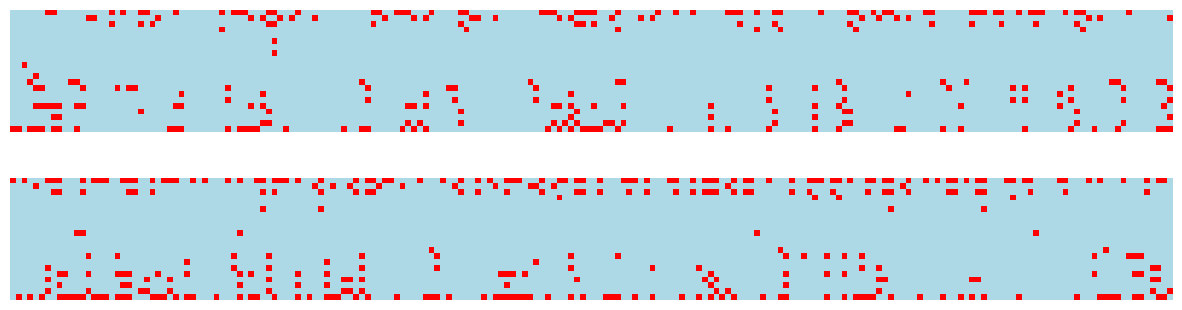

In [78]:
# bitmap of routing using LR
cmap = ListedColormap(["red", "lightblue"])

fig, axs = plt.subplots(2, 1, figsize=(15, 4))

bitmap_lr_slice = [row[:200] for row in bitmap_singleskip_lr]
axs[0].imshow(bitmap_lr_slice, cmap=cmap, interpolation="nearest")
axs[0].axis("off")
bitmap_lr_slice = [row[250000:250200] for row in bitmap_singleskip_lr]
axs[1].imshow(bitmap_lr_slice, cmap=cmap, interpolation="nearest")
axs[1].axis("off")
plt.show()

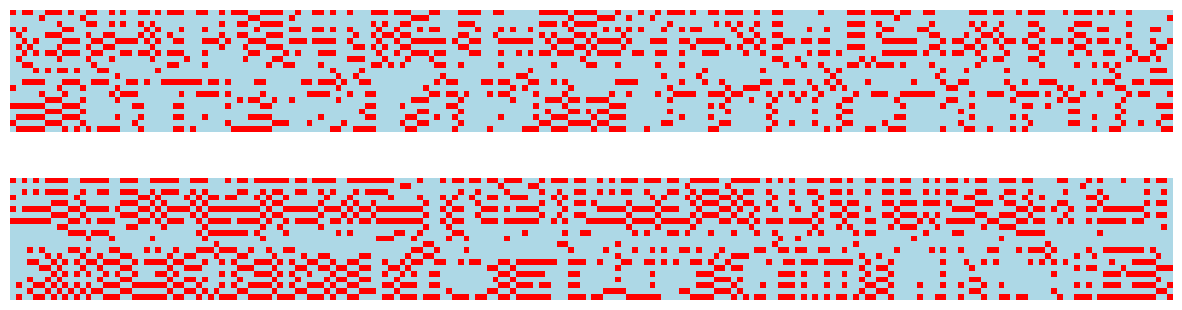

In [79]:
# bitmap of routing using MLP
fig, axs = plt.subplots(2, 1, figsize=(15, 4))

bitmap_mlp_slice = [row[:200] for row in bitmap_singleskip_mlp]
axs[0].imshow(bitmap_mlp_slice, cmap=cmap, interpolation="nearest")
axs[0].axis("off")
bitmap_mlp_slice = [row[250000:250200] for row in bitmap_singleskip_mlp]
axs[1].imshow(bitmap_mlp_slice, cmap=cmap, interpolation="nearest")
axs[1].axis("off")
plt.show()

## SingleSkip Top-k Router

In [42]:
class SingleSkipTopKRouter(nn.Module):
    def __init__(self, predictor, mlp, k=0.7, prev_router=None, save_bitmap=True):
        super().__init__()
        self.predictor = predictor
        self.mlp = mlp
        self.k = k
        self.prev_router = prev_router
        self.n_total = 0
        self.n_mlp = 0
        self.save_bitmap = save_bitmap
        if save_bitmap:
            self.bitmap = []
        self.latest_decision = []
        
    def forward(self, x):
        bsz, seq_len, dim = x.shape
        
        previous = self.prev_router.latest_decision if self.prev_router else np.ones(bsz * seq_len).astype(bool)
        candidates = x[:, previous]        # only these tokens can be skipped
        candidate_probs = self.predictor.predict_proba(candidates.to(torch.float))
        
        # tokens for which the previous layer was skipped will be assigned proba=1
        use_mlp_probs = np.ones((seq_len, bsz))
        use_mlp_probs[previous] = candidate_probs
        use_mlp_probs = torch.Tensor(use_mlp_probs)
        
        x_flat = x.view(-1, dim)

        k_per_row = max(1, int(seq_len * self.k))  # ensure at least 1

        selected_idx = torch.topk(use_mlp_probs, k_per_row, dim=0).indices.flatten()  # (bsz, k_per_row)
        use_mlp_flat = np.zeros(bsz * seq_len, dtype=bool)
        use_mlp_flat[selected_idx] = True
        
        self.n_mlp += selected_idx.numel()
        self.n_total += use_mlp_probs.numel()
        # Apply MLP only to selected tokens
        out = torch.zeros_like(x_flat)  # same shape as input
        if selected_idx.numel():
            selected = x_flat[use_mlp_flat]  # (N_selected, dim)
            mlp_out = self.mlp(selected)     # (N_selected, dim)
            out[use_mlp_flat] = mlp_out      # insert results
            self.latest_decision = use_mlp_flat
            if self.save_bitmap:
                self.bitmap.extend(use_mlp_flat.tolist())
        return out.view(bsz, seq_len, dim)
        

In [36]:
def eval_model_singleskip_topk(use_router='', results_router=None, layer_stats=None, k=0.7, save_bitmap=False):
    if results_router is None:
        index = pd.MultiIndex.from_tuples([], names=["k", "router_type"])
        results_router = pd.DataFrame(columns=["perplexity", "del_ratio", "inference_time"], index=index)

    if use_router:
        predictor_quality = pd.read_csv('prediction_results.csv', index_col=0)
        auc_col = 'AUC' if use_router == 'lr' else 'AUC_mlp'
        
        prev_router = None
        for i, layer in enumerate(model.model.layers):
            if i in layers_to_keep:
                prev_router = None
                continue
            predictor = layer.predictor[use_router]
            mlp_copy = copy.deepcopy(layer.mlp)
            layer.mlp = SingleSkipTopKRouter(predictor, mlp_copy, k=k, prev_router=prev_router, save_bitmap=save_bitmap)
            prev_router = layer.mlp
    
    # measure performance
    t0 = time.time()
    ppl = eval_ppl(model, wiki_testloader, device=DEV)
    t = time.time() - t0

    global_skip_ratio = 0
    routing_bitmap = []
    
    if use_router:
        sum_n_total = sum_n_skipped = 0
        column_name = use_router

        for i, layer in enumerate(model.model.layers):
            if i in layers_to_keep:
                continue

            n_total = layer.mlp.n_total
            n_skipped = n_total - layer.mlp.n_mlp
            skip_ratio = n_skipped / n_total if n_total > 0 else 0

            sum_n_skipped += n_skipped

            if save_bitmap:
                routing_bitmap.append(layer.mlp.bitmap)

            layer.mlp = copy.deepcopy(layer.mlp.mlp)  # restore

        sum_n_total = n_total * len(model.model.layers)
        global_skip_ratio = sum_n_skipped / sum_n_total
    
    results_router.loc[(k, use_router), :] = [ppl, global_skip_ratio, t]
    return {'results_router': results_router, 'routing_bitmap': routing_bitmap}

In [37]:
results_singleskip_topk_dict = eval_model_singleskip_topk('lr', k=0.9)
results_singleskip_topk_dict = eval_model_singleskip_topk('nn', k=0.9, results_router=results_singleskip_topk_dict['results_router'])

results_singleskip_topk_dict = eval_model_singleskip_topk('lr', k=0.8, results_router=results_singleskip_topk_dict['results_router'])
results_singleskip_topk_dict = eval_model_singleskip_topk('nn', k=0.8, results_router=results_singleskip_topk_dict['results_router'])

results_singleskip_topk_dict = eval_model_singleskip_topk('lr', k=0.7, results_router=results_singleskip_topk_dict['results_router'], save_bitmap=True)
bitmap_singleskip_topk_lr = results_singleskip_topk_dict['routing_bitmap']
results_singleskip_topk_dict = eval_model_singleskip_topk('nn', k=0.7, results_router=results_singleskip_topk_dict['results_router'], save_bitmap=True)
bitmap_singleskip_topk_mlp = results_singleskip_topk_dict['routing_bitmap']

results_singleskip_topk_dict = eval_model_singleskip_topk('lr', k=0.6, results_router=results_singleskip_topk_dict['results_router'])
results_singleskip_topk_dict = eval_model_singleskip_topk('nn', k=0.6, results_router=results_singleskip_topk_dict['results_router'])


results_singleskip_topk_dict['results_router'].to_csv('results_router_singleskip_topk.csv')
results_singleskip_topk_dict['results_router']

perplexity del_ratio inference_time
k   router_type                                    
0.9 lr           20.000896  0.087585      10.147492
    nn            8.288465  0.087585      10.177309
0.8 lr             10.8422  0.175064       9.666372
    nn           10.851363  0.175064       9.737457
0.7 lr           20.068583  0.262543         9.3482
    nn           18.552568  0.262543       9.415622
0.6 lr           58.538185  0.350021       8.855054
    nn           46.700272  0.350021       8.893918

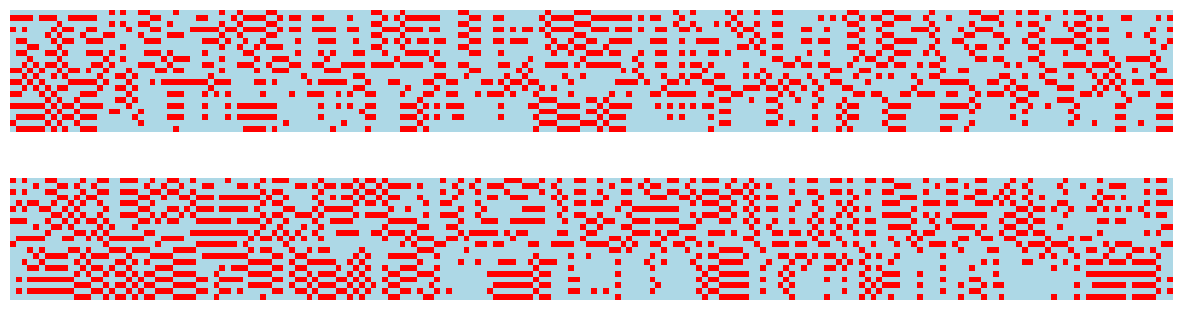

In [40]:
# bitmap of routing using LR
cmap = ListedColormap(["red", "lightblue"])

fig, axs = plt.subplots(2, 1, figsize=(15, 4))

bitmap_slice = [row[:200] for row in bitmap_singleskip_topk_lr]
axs[0].imshow(bitmap_slice, cmap=cmap, interpolation="nearest")
axs[0].axis("off")
bitmap_slice = [row[250000:250200] for row in bitmap_singleskip_topk_lr]
axs[1].imshow(bitmap_slice, cmap=cmap, interpolation="nearest")
axs[1].axis("off")
plt.show()

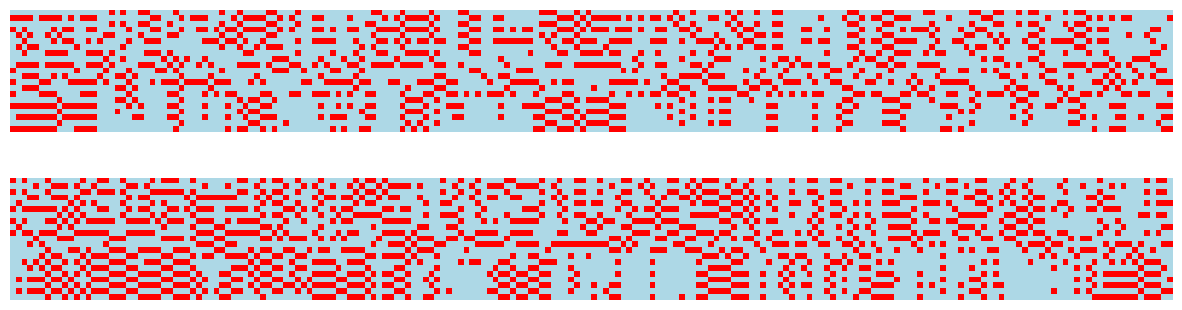

In [39]:
# bitmap of routing using MLP
cmap = ListedColormap(["red", "lightblue"])

fig, axs = plt.subplots(2, 1, figsize=(15, 4))

bitmap_slice = [row[:200] for row in bitmap_singleskip_topk_mlp]
axs[0].imshow(bitmap_slice, cmap=cmap, interpolation="nearest")
axs[0].axis("off")
bitmap_slice = [row[250000:250200] for row in bitmap_singleskip_topk_mlp]
axs[1].imshow(bitmap_slice, cmap=cmap, interpolation="nearest")
axs[1].axis("off")
plt.show()

## Random Routers Not Skipping Two Layers In Row

In [12]:
class RndSingleSkipRouter(nn.Module):
    def __init__(self, mlp, prev_router=None, p_skip=0.3, save_bitmap=True):
        super().__init__()
        # self.predictor = predictor
        self.mlp = mlp
        self.p_skip = p_skip
        self.prev_router = prev_router
        self.n_total = 0
        self.n_mlp = 0
        self.save_bitmap = save_bitmap
        if save_bitmap:
            self.bitmap = []
        self.latest_decision = []
        
    def forward(self, x):
        bsz, seq_len, dim = x.shape
        x_flat = x.view(-1, dim)
        use_mlp_flat = np.random.choice([0, 1], size=(bsz * seq_len,), p=[self.p_skip, 1-self.p_skip]).astype(bool)
        # avoid skipping two layers in a row for the same token
        previous = self.prev_router.latest_decision if self.prev_router else np.ones_like(use_mlp_flat)
        use_mlp_flat = use_mlp_flat | ~previous
        
        self.n_mlp += use_mlp_flat.sum()
        self.n_total += use_mlp_flat.size
        # Apply MLP only to selected tokens
        out = torch.zeros_like(x_flat)  # same shape as input
        if use_mlp_flat.any():
            selected = x_flat[use_mlp_flat]  # (N_selected, dim)
            mlp_out = self.mlp(selected)     # (N_selected, dim)
            out[use_mlp_flat] = mlp_out      # insert results
            self.latest_decision = use_mlp_flat
            if self.save_bitmap:
                self.bitmap.extend(use_mlp_flat.tolist())

        return out.view(bsz, seq_len, dim)
        

In [13]:
def eval_model_rnd_singleskip(p_skip=0.3, results_router=None, layer_stats=None, save_bitmap=False):
    if layer_stats is None:
        layer_stats = pd.DataFrame()
    if results_router is None:
        results_router = pd.DataFrame(columns=["perplexity", "del_ratio", "inference_time"])

    prev_router = None
    for i, layer in enumerate(model.model.layers):
        if i in layers_to_keep:
            prev_router = None
            continue
        mlp_copy = copy.deepcopy(layer.mlp)
        layer.mlp = RndSingleSkipRouter(mlp_copy, prev_router=prev_router, p_skip=p_skip, save_bitmap=save_bitmap)
        prev_router = layer.mlp
    
    # measure performance
    t0 = time.time()
    ppl = eval_ppl(model, wiki_testloader, device=DEV)
    t = time.time() - t0

    global_skip_ratio = 0
    routing_bitmap = []
    
    sum_n_total = sum_n_skipped = 0

    for i, layer in enumerate(model.model.layers):
        if i in layers_to_keep:
            continue

        n_total = layer.mlp.n_total
        n_skipped = n_total - layer.mlp.n_mlp
        skip_ratio = n_skipped / n_total if n_total > 0 else 0

        sum_n_skipped += n_skipped
        
        if save_bitmap:
            routing_bitmap.append(layer.mlp.bitmap)

        layer_stats.at[i, p_skip] = skip_ratio
        layer.mlp = copy.deepcopy(layer.mlp.mlp)  # restore

    sum_n_total = n_total * len(model.model.layers)
    global_skip_ratio = sum_n_skipped / sum_n_total
    layer_stats.at['all', p_skip] = global_skip_ratio
    
    results_router.loc[p_skip] = [ppl, global_skip_ratio, t]
    return {'results_router': results_router, 'layer_stats': layer_stats, 'routing_bitmap': routing_bitmap}

In [16]:
results_rnd_singleskip_dict = eval_model_rnd_singleskip(p_skip=0.2)
results_rnd_singleskip_dict = eval_model_rnd_singleskip(p_skip=0.3, save_bitmap=True, 
    results_router=results_rnd_singleskip_dict['results_router'], layer_stats=results_rnd_singleskip_dict['layer_stats'])
bitmap_rnd_singleskip = results_rnd_singleskip_dict['routing_bitmap']
results_rnd_singleskip_dict = eval_model_rnd_singleskip(p_skip=0.4, 
    results_router=results_rnd_singleskip_dict['results_router'], layer_stats=results_rnd_singleskip_dict['layer_stats'])
results_rnd_singleskip_dict['results_router'].to_csv('results_rnd_singleskip_router.csv')
results_rnd_singleskip_dict['results_router']

,perplexity,del_ratio,inference_time
0.2,28.722643,0.147122,8.942342
0.3,37.146332,0.204049,8.722564
0.4,114.951492,0.253367,8.586700


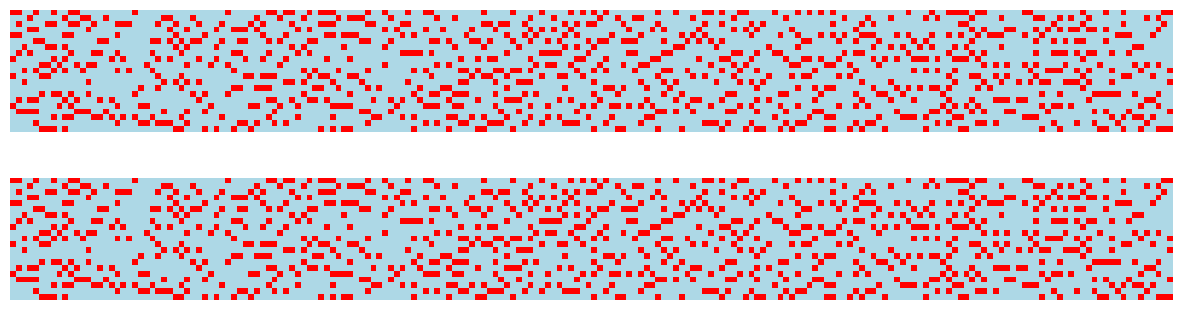

In [17]:
cmap = ListedColormap(["red", "lightblue"])

fig, axs = plt.subplots(2, 1, figsize=(15, 4))

bitmap_mlp_slice = [row[:200] for row in bitmap_rnd_singleskip]
axs[0].imshow(bitmap_mlp_slice, cmap=cmap, interpolation="nearest")
axs[0].axis("off")
bitmap_lr_slice = [row[250000:250200] for row in bitmap_rnd_singleskip]
axs[1].imshow(bitmap_mlp_slice, cmap=cmap, interpolation="nearest")
axs[1].axis("off")
plt.show()